# Trained pilot motion forecasting

Predict A01 (a trained pilot) from B01 (the scripted tactical observer) at **1, 2 and 5 seconds**. This notebook reads the completed initial experiment and demonstrates checkpoint inference. **Run All does not retrain models or evaluate the reserved test set.**

The transformer and GRU receive 51 tokens covering five seconds. Three backward acceleration features extend the raw observation dependency to 5.5 seconds: 56 raw frames supply 51 model tokens. Inputs contain no private target decisions or pilot identity. See [the forecasting guide](../docs/motion_forecasting.md) for the full protocol.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT))
RUN = ROOT / 'artifacts/motion_forecasting/initial_v1'
DATA = ROOT / 'artifacts/motion_forecasting/data_v1'
CORPUS = ROOT / 'shared/corpora/trained-pilot-episodes-v1'
if not (RUN / 'validation_comparison.csv').exists():
    raise FileNotFoundError('Generate the forecasting report with scripts/train_motion_forecaster.py report; see docs/motion_forecasting.md')
metrics = pd.read_csv(RUN / 'validation_comparison.csv')
read_json = lambda path: json.loads(path.read_text(encoding='utf-8'))
print('Results:', RUN)
print('Reserved test performance has not been evaluated.')

Results: C:\Users\jttur\VSCodeProjects\Trajectory_Classification\artifacts\motion_forecasting\initial_v1
Reserved test performance has not been evaluated.


## Data partitions

All encounters from one matched starting scenario remain in the same partition across all ten pilots. Scaling is fitted on training data only. Future targets are independently masked at each horizon when unavailable or after target destruction.

In [2]:
data_manifest = read_json(DATA / 'data_manifest.json')
partition_rows = []
for split, counts in data_manifest['counts'].items():
    partition_rows.append({'partition': split, 'scenario groups': counts['scenario_groups'],
                           'episodes': counts['episodes'], 'forecast origins': counts['samples'],
                           **{f'valid {h}s targets': n for h, n in zip([1, 2, 5], counts['valid_by_horizon'])}})
display(pd.DataFrame(partition_rows).set_index('partition'))

,scenario groups,episodes,forecast origins,valid 1s targets,valid 2s targets,valid 5s targets
partition,,,,,,
train,210,2100,147718,147718,146191,141544
validation,45,450,31029,31029,30693,29685
test,45,450,32457,32457,32099,31025


## Architecture and checkpoint selection

Both networks predict 18 residual values: three position and three velocity corrections for each horizon. They start at constant velocity, then learn with masked, scaled Huber loss. Selection uses validation error relative to constant velocity, averaged equally over the six position/velocity/horizon combinations. Lower is better; 1 means baseline performance.

In [3]:
model_rows = []
for name in ['transformer', 'gru']:
    run, summary = read_json(RUN / name / 'run.json'), read_json(RUN / name / 'summary.json')
    model_rows.append({'model': name, 'width': run['model']['width'], 'layers': run['model']['layers'],
                       'attention heads per block': run['model']['heads'] if name == 'transformer' else '-',
                       'parameters': run['parameters'], 'epochs completed': summary['epochs_completed'],
                       'selected epoch': summary['best_epoch'], 'validation score': summary['validation_score']})
display(pd.DataFrame(model_rows).set_index('model'))

,width,layers,attention heads per block,parameters,epochs completed,selected epoch,validation score
model,,,,,,,
transformer,128,2,4,429202,29,22,0.073605
gru,128,2,-,224274,30,28,0.075304


## Population validation results

Position errors are in **metres** and velocity errors in **metres per second**. Each error is the length of the 3D error vector. Errors average within episodes, then across episodes, so long encounters do not dominate. These are validation results for model development, not final test results.

quantity              position                  velocity                
horizon_s                  1.0     2.0      5.0      1.0     2.0     5.0
model                                                                   
constant_acceleration    0.867   5.227   63.943    2.181   7.026  35.642
constant_velocity        9.146  36.177  221.456   17.914  35.706  86.968
gru                      0.440   1.927   20.655    0.906   2.402  12.113
transformer              0.484   2.022   19.092    0.976   2.369  10.937

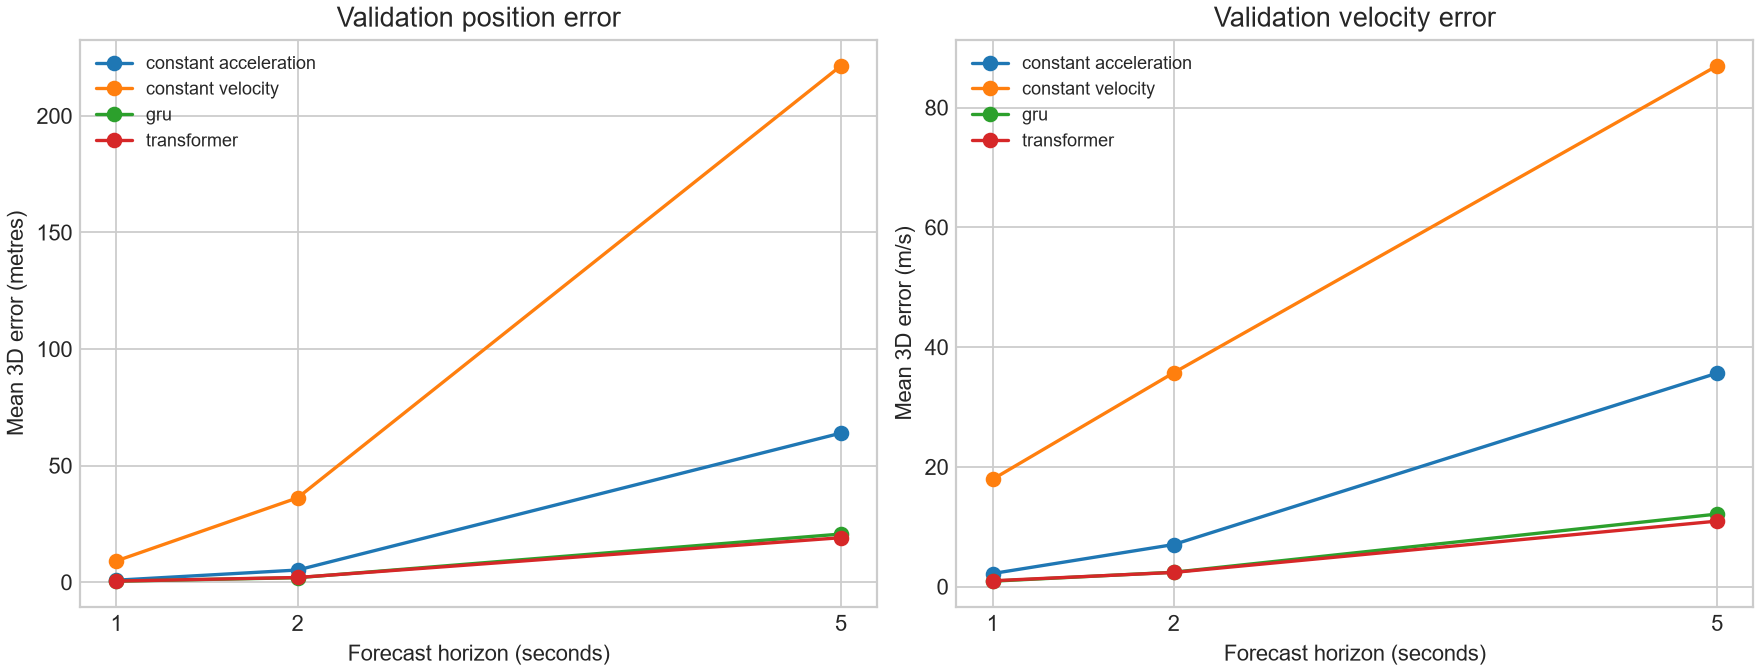

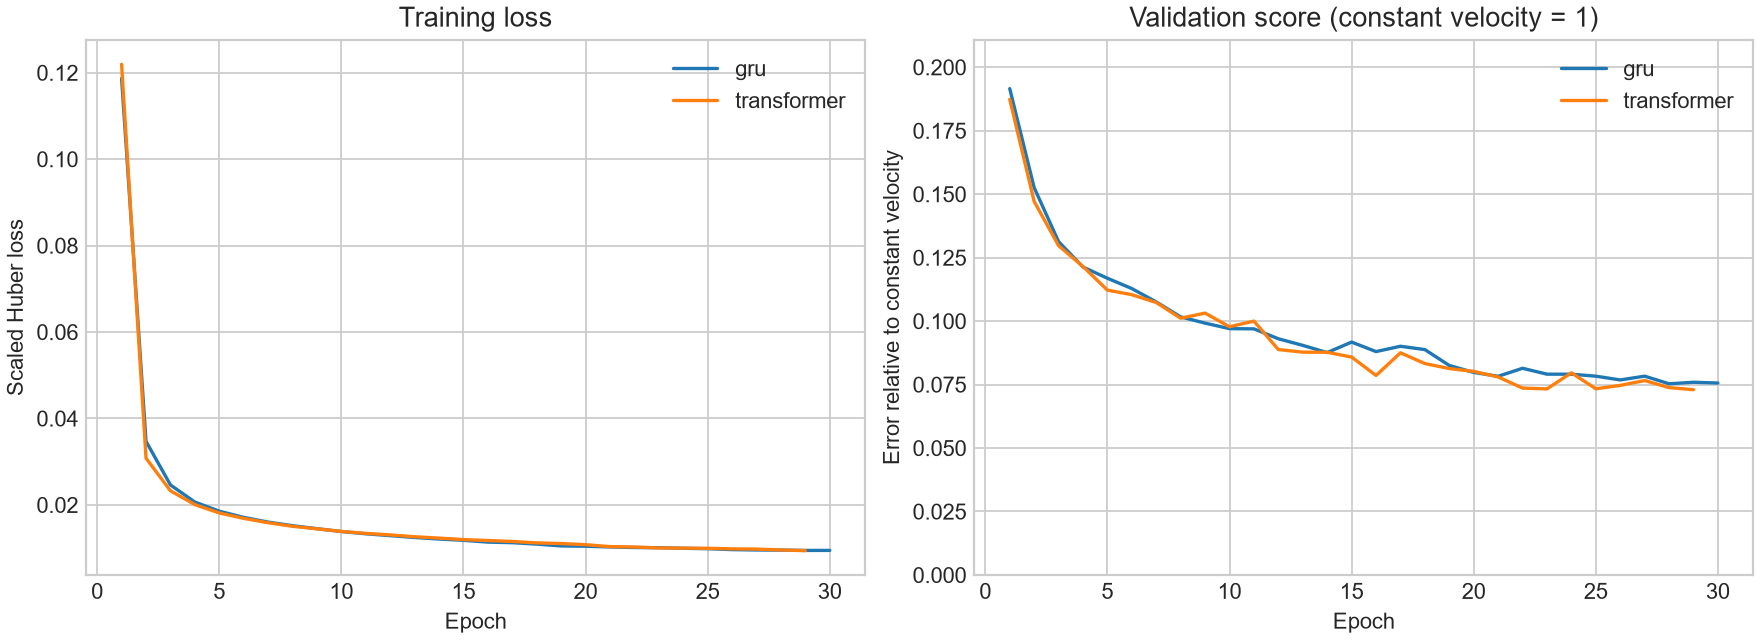

In [4]:
population = metrics[metrics.pilot_id == 'population']
table = population.pivot(index='model', columns=['quantity', 'horizon_s'], values='episode_mean_error')
table = table.reindex(columns=pd.MultiIndex.from_product([['position', 'velocity'], [1., 2., 5.]], names=['quantity', 'horizon_s']))
display(table.round(3))
display(Image(filename=str(RUN / 'validation_errors.png')))
display(Image(filename=str(RUN / 'learning_curves.png')))

## Per-pilot validation results

Change `HORIZON_S` to 1, 2 or 5. Pilot identity is used for reporting only, not as a model feature.

In [5]:
HORIZON_S = 5
per_pilot = metrics[(metrics.pilot_id != 'population') & (metrics.horizon_s == HORIZON_S) & metrics.model.isin(['transformer', 'gru'])]
display(per_pilot.pivot(index='pilot_id', columns=['model', 'quantity'], values='episode_mean_error').round(3))

model          gru          transformer         
quantity  position velocity    position velocity
pilot_id                                        
pilot_001   13.864    8.091      12.486    7.207
pilot_002   25.868   15.600      25.087   14.787
pilot_003   15.091    8.864      14.068    8.055
pilot_004   19.468   11.348      16.575    9.295
pilot_005   26.547   15.548      24.681   13.881
pilot_006   25.167   14.416      22.911   13.040
pilot_007   17.897   10.389      17.022    9.661
pilot_008   16.446    9.941      14.812    8.767
pilot_009   26.503   15.156      24.108   13.457
pilot_010   19.696   11.779      19.165   11.221

## Forecast from one observation history

This example reloads the selected transformer on CPU and uses only observations at or before one validation forecast origin. Outputs are future absolute world North/West/Up coordinates, not latitude/longitude. Supply at least 56 consecutive raw frames at 10 Hz using the dataset's existing 51-feature scales.

In [6]:
import torch
from bvr_behavior_prediction.forecasting.inference import MotionPredictor
torch.set_num_threads(4)
sample = pd.read_parquet(RUN / 'transformer/validation_samples.parquet').iloc[0]
episode = pd.read_parquet(CORPUS / 'observations' / f'{sample.pilot_id}.parquet', filters=[('episode_id', '==', sample.episode_id)])
observed_history = episode.loc[episode.step <= sample.step, [f'obs_{i:02d}' for i in range(51)]].to_numpy()
predictor = MotionPredictor(RUN / 'transformer/best.pt', device='cpu')
forecast = predictor.predict(observed_history)
print(f'Episode {sample.episode_id}; forecast origin {sample.time_s:.1f}s')
display(pd.DataFrame(np.concatenate([forecast['position_nwu_m'], forecast['velocity_nwu_mps']], axis=1),
                     index=pd.Index(forecast['horizons_s'], name='horizon_s'),
                     columns=['north_m', 'west_m', 'up_m', 'v_north_mps', 'v_west_mps', 'v_up_mps']).round(3))

Episode pilot_001_case_0000; forecast origin 6.0s


,north_m,west_m,up_m,v_north_mps,v_west_mps,v_up_mps
horizon_s,,,,,,
1.0,-5648.877,3915.125,4355.216,201.960,-238.957,-35.702
2.0,-5451.343,3671.321,4318.867,193.203,-248.381,-36.825
5.0,-4914.644,2887.311,4205.871,164.192,-273.251,-38.364


## Further experiments

Keep the initial runs and fixed partitions. Use a new output directory and an explicit configuration for another model experiment. Training commands and resume instructions are in [the guide](../docs/motion_forecasting.md).

The current validation covers new starting scenarios for known trained pilots with idealised observations. Unseen pilots, noisy sensors, uncertainty estimates and named manoeuvre classification require additional experiments. The reserved final test should remain unused while these choices are being developed.